# NakEna — Training YOLOv8 dengan 3 Dataset Roboflow

**Bahan-Makanan Skripsi + Food Ingredient_V2 + AICook**, diunduh langsung ke Colab.
Alur: cek sumber → download → audit label → samakan kelas → kelompokkan duplikat/foto mirip
→ train/val/test → training → evaluasi foto campuran → uji foto sendiri → unduh `best.pt`.

**Sebelum mulai:** aktifkan GPU T4 melalui Runtime → Change runtime type → T4 GPU.
Gunakan **private API key Roboflow**, bukan API key Gemini. Tidak perlu upload ZIP dataset.

| Sumber | Versi awal | Catatan |
|---|---:|---|
| [Bahan-Makanan Skripsi](https://universe.roboflow.com/skripsi-gnafx/bahan-makanan-lklbu/dataset/3) | 3 | Halaman versi: 63.701 gambar, seluruhnya di train, tanpa augmentasi offline |
| [Food Ingredient_V2](https://universe.roboflow.com/cquangs-workspace/food-ingredient_v2) | Dideteksi saat runtime | Saat notebook disusun: 17.711 gambar, **belum ada versi ekspor publik** |
| [AICook](https://universe.roboflow.com/karel-cornelis-q2qqg/aicook-lcv4d/dataset/1) | 1 | 516 gambar asli; menghindari unduhan versi augmentasi 3.050 gambar |

**Food Ingredient_V2:** sel 3 mencoba membuat salinan/fork dan versi tanpa augmentasi di workspace
Roboflow milikmu, jika sumber belum punya versi. Ini menambah project/data di akun Roboflow,
memerlukan izin tulis dan kuota gambar. Tidak menjalankan training berbayar di Roboflow.
Jika izin/kuota tidak cukup, sel berhenti dengan petunjuk; dataset ketiga tidak dilewati diam-diam.
Kamu juga bisa memakai salinan yang sudah dibuat dengan mengisi workspace/project/versinya di sel 1.

Untuk eksperimen pertama, profil **uji_awal** membatasi data setelah audit menjadi maksimal
6.000 train + 750 val + 750 test per sumber besar, serta mempertahankan seluruh gambar AICook yang lolos.
Seluruh ekspor tetap diunduh dan diaudit. Ganti profil menjadi **penuh** untuk memakai seluruh data yang lolos.
Ukuran gabungan, jumlah kelas, serta proporsi foto campuran dihitung dari hasil unduhan, bukan ditebak.


## 1. Instal dan pengaturan

Default training: **YOLOv8s, 25 epoch, input 800, batch 8**, sebagai percobaan perubahan dataset.
Durasi bergantung GPU dan jumlah gambar. Mode penuh jauh lebih lama daripada uji awal.
Aktifkan penyimpanan Drive agar checkpoint tetap ada jika runtime Colab terputus.


In [1]:
%pip -q install --upgrade ultralytics roboflow pyyaml pandas pillow matplotlib tqdm


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.1 which is incompatible.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.
dask-cudf-cu13 26.6.0 requires pandas<2.4.0,>=2.0, but you have pandas 3.1.1 which is incompatible.


In [2]:
from pathlib import Path
import json, os, random, time, shutil, hashlib
import torch
import pandas as pd
from IPython.display import display

PROFILE = "uji_awal"  # @param ["uji_awal", "penuh"]
EPOCHS = 25  # @param {type:"integer"}
IMGSZ = 800  # @param {type:"integer"}
BATCH = 8  # @param {type:"integer"}
SEED = 42
USE_DRIVE = True  # @param {type:"boolean"}

# Jika sudah punya fork Food Ingredient_V2, isi ketiga kolom ini sesuai kode ekspornya.
FOOD_V2_WORKSPACE = ""  # @param {type:"string"}
FOOD_V2_PROJECT = "food-ingredient_v2"  # @param {type:"string"}
FOOD_V2_VERSION = 0  # @param {type:"integer"}
# 0 = pilih versi terbaru yang tersedia; angka >0 = versi tersebut.
AUTO_PREPARE_FOOD_V2 = True  # @param {type:"boolean"}
TARGET_WORKSPACE = ""  # @param {type:"string"}
# Kosong = workspace default untuk key Roboflow. Isi slug jika punya beberapa workspace.

# dHash mengelompokkan foto mirip, bukan menghapusnya. None menonaktifkan heuristik ini.
NEAR_HASH_DISTANCE = 2
CLASS_OVERRIDES = {}  # Contoh setelah diperiksa: {"nama_asal": "Nama Kelas Benar"}
# Label numerik seperti '0' dikarantina bersama seluruh fotonya sampai artinya jelas.
RESUME_FROM = ""  # @param {type:"string"}
# Untuk melanjutkan run terputus, isi path last.pt dari Drive dan gunakan profil/data yang sama.

ROOT = Path("/content/NakEnaMerged")
ROOT.mkdir(parents=True, exist_ok=True)
RAW_DIR = ROOT / "raw"
RAW_DIR.mkdir(exist_ok=True)
if USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    OUTPUT_ROOT = Path("/content/drive/MyDrive/NakEna_YOLO_Gabungan")
else:
    OUTPUT_ROOT = ROOT / "outputs"
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
STATE_DIR = OUTPUT_ROOT / "state"
STATE_DIR.mkdir(exist_ok=True)
MERGED_DIR = ROOT / ("merged_" + PROFILE)

print("Profil:", PROFILE)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "belum aktif")
print("Checkpoint:", OUTPUT_ROOT)
print("Ruang lokal kosong: %.1f GB" % (shutil.disk_usage('/content').free / 2**30))


/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Mounted at /content/drive
Profil: uji_awal
GPU: NVIDIA A100-SXM4-80GB
Checkpoint: /content/drive/MyDrive/NakEna_YOLO_Gabungan
Ruang lokal kosong: 235.4 GB


## 2. Hubungkan Roboflow

Masukkan **private API key Roboflow** pada input tersembunyi. Alternatif: buat Colab Secret
bernama `ROBOFLOW_API_KEY` dan aktifkan akses notebook. Key tidak ditulis ke laporan atau paket model.


In [5]:
from getpass import getpass
from roboflow import Roboflow
_rf_key = ""
try:
    from google.colab import userdata
    _rf_key = userdata.get("ROBOFLOW_API_KEY") or ""
except Exception:
    pass
if not _rf_key:
    _rf_key = getpass("Private API key Roboflow: ")
if not _rf_key.strip():
    del _rf_key
    raise ValueError("API key Roboflow masih kosong.")
rf = Roboflow(api_key=_rf_key.strip())
del _rf_key
print("Roboflow siap. Key tidak ditampilkan.")


Private API key Roboflow: ··········
Roboflow siap. Key tidak ditampilkan.


## 3. Periksa versi dan siapkan Food Ingredient_V2

Versi yang dipilih dicatat agar eksperimen bisa ditelusuri. Jika Food Ingredient_V2 belum punya
versi ekspor, sel ini dapat membuat **fork satu kali dan versi data** di workspace-mu.
Proses penyalinan bisa memerlukan waktu. Statusnya disimpan agar sel dapat dilanjutkan.

Jika otomatisasi tidak didukung akun/SDK: buka tautan sumber → **Fork Dataset** → pilih workspace →
**Generate/Create New Version** dengan Auto-Orient, tanpa augmentasi offline. Isi identitas salinan
di sel 1 dari kode ekspor YOLOv8, lalu ulangi sel 1–3. Label sumber ikut disalin.


In [6]:
from urllib.parse import urlparse

def versions_of(project):
    return sorted({int(str(v.version).rstrip("/").split("/")[-1]) for v in project.versions()})

def pick_version(project, requested):
    versions = versions_of(project)
    if not versions:
        raise RuntimeError("Project belum mempunyai versi ekspor.")
    selected = requested if requested else max(versions)
    if selected not in versions:
        raise RuntimeError(f"Versi {selected} tidak tersedia; versi yang ditemukan: {versions}")
    return selected

def save_state(path, data):
    temp = path.with_suffix(".tmp")
    temp.write_text(json.dumps(data, indent=2), encoding="utf-8")
    temp.replace(path)

def fork_project_slug(payload):
    # Gunakan URL yang benar-benar dikembalikan SDK, jangan menebak slug hasil fork.
    for key in ("url", "projectUrl", "project_url"):
        value = payload.get(key)
        if isinstance(value, str) and value:
            parts = urlparse(value).path.strip("/").split("/")
            if parts and parts[-1]: return parts[-1]
    for value in payload.values():
        if isinstance(value, dict):
            found = fork_project_slug(value)
            if found: return found
    return None

def prepare_food_v2():
    if FOOD_V2_WORKSPACE.strip():
        workspace = FOOD_V2_WORKSPACE.strip()
        project = rf.workspace(workspace).project(FOOD_V2_PROJECT.strip())
        version = pick_version(project, FOOD_V2_VERSION)
        return workspace, FOOD_V2_PROJECT.strip(), version

    source = rf.workspace("cquangs-workspace").project("food-ingredient_v2")
    available = versions_of(source)
    if available:
        return "cquangs-workspace", "food-ingredient_v2", pick_version(source, FOOD_V2_VERSION)
    if not AUTO_PREPARE_FOOD_V2:
        raise RuntimeError("Food Ingredient_V2 belum punya versi. Buat fork+versi sesuai petunjuk, lalu isi sel 1.")

    own = rf.workspace(TARGET_WORKSPACE.strip()) if TARGET_WORKSPACE.strip() else rf.workspace()
    own_slug = own.url
    state_path = STATE_DIR / ("food_v2_" + re_safe(own_slug) + ".json")
    state = json.loads(state_path.read_text()) if state_path.exists() else {}
    if not state:
        if not hasattr(own, "fork_project"):
            raise RuntimeError("SDK akun ini belum mendukung fork_project. Gunakan Fork Dataset pada web, lalu isi sel 1.")
        print(f"Membuat salinan Food Ingredient_V2 di workspace {own_slug}...")
        response = own.fork_project(url="https://universe.roboflow.com/cquangs-workspace/food-ingredient_v2")
        state = {"fork_response": response, "workspace": own_slug}
        save_state(state_path, state)

    response = state["fork_response"]
    task_id = response.get("taskId") or response.get("task_id")
    if task_id and not state.get("fork_done"):
        deadline = time.monotonic() + 1800
        while time.monotonic() < deadline:
            task = own.get_async_task(task_id)
            payload = task.get("task", task)
            status = str(payload.get("status", payload.get("state", ""))).casefold()
            if status in {"done", "completed", "complete", "succeeded", "success"} or payload.get("done") is True:
                state["fork_done"] = True
                state["task_result"] = task
                save_state(state_path, state)
                break
            if status in {"failed", "error", "cancelled", "canceled"}:
                raise RuntimeError("Fork gagal di Roboflow. Periksa izin dan kuota gambar pada workspace, atau buat fork melalui web.")
            print(f"Menunggu fork: {status or 'diproses'}", end="\r")
            time.sleep(5)
        else:
            raise RuntimeError("Fork masih diproses. Periksa project di Roboflow, lalu ulangi sel 3; status sudah disimpan.")
    slug = state.get("project") or fork_project_slug(state.get("task_result", {})) or fork_project_slug(response)
    if not slug:
        raise RuntimeError("Slug hasil fork belum tersedia dari API. Isi workspace/project salinan di sel 1 setelah fork selesai.")
    state["project"] = slug
    save_state(state_path, state)
    project = own.project(slug)
    if int(project.images) <= 0:
        raise RuntimeError("Salinan belum berisi gambar. Tunggu penyalinan selesai, lalu ulangi sel 3.")
    available = versions_of(project)
    if available:
        version = pick_version(project, FOOD_V2_VERSION)
    elif state.get("version"):
        version = state["version"]
    else:
        print("Membuat versi tanpa augmentasi offline...")
        version = project.generate_version({"preprocessing": {"auto-orient": True}, "augmentation": {}})
        state["version"] = int(version)
        save_state(state_path, state)
    return own_slug, slug, int(version)

def re_safe(value):
    return "".join(c if c.isalnum() or c in "-_" else "_" for c in str(value))

RESOLVED_SOURCES = []
try:
    # Periksa sumber yang paling mungkin memerlukan persiapan sebelum mengunduh puluhan ribu foto.
    food_ws, food_project, food_version = prepare_food_v2()
    specs = [
        {"key": "skripsi", "workspace": "skripsi-gnafx", "project": "bahan-makanan-lklbu", "version": 3, "license": "CC BY 4.0"},
        {"key": "food_v2", "workspace": food_ws, "project": food_project, "version": food_version, "license": "CC BY 4.0"},
        {"key": "aicook", "workspace": "karel-cornelis-q2qqg", "project": "aicook-lcv4d", "version": 1, "license": "MIT"},
    ]
    for spec in specs:
        project = rf.workspace(spec["workspace"]).project(spec["project"])
        spec["version"] = pick_version(project, spec["version"])
        RESOLVED_SOURCES.append(spec)
except Exception as exc:
    RESOLVED_SOURCES = []
    # Pesan SDK dapat memuat URL bertoken; tampilkan instruksi tanpa kredensial.
    if isinstance(exc, RuntimeError) and not any(x in str(exc).lower() for x in ("api_key", "https://", "http://")):
        message = str(exc)[:500]
    else:
        message = "Akses Roboflow gagal. Periksa private API key, izin project, kuota fork/generate, dan ketersediaan versi. Alternatif: fork Food Ingredient_V2 di web dan isi sel 1."
    raise RuntimeError(message) from None

assert len(RESOLVED_SOURCES) == 3
save_state(STATE_DIR / "resolved_sources.json", {"sources": RESOLVED_SOURCES})
display(pd.DataFrame(RESOLVED_SOURCES))


loading Roboflow workspace...
loading Roboflow project...
loading Roboflow workspace...
Membuat salinan Food Ingredient_V2 di workspace 4b_putu-radit-ardika...
loading Roboflow project...
Membuat versi tanpa augmentasi offline...
Dataset version generation initialized for new version 1.
loading Roboflow workspace...
loading Roboflow project...
loading Roboflow workspace...
loading Roboflow project...
loading Roboflow workspace...
loading Roboflow project...


,key,workspace,project,version,license
0,skripsi,skripsi-gnafx,bahan-makanan-lklbu,3,CC BY 4.0
1,food_v2,4b_putu-radit-ardika,food-ingredient_v2-mvdf5,1,CC BY 4.0
2,aicook,karel-cornelis-q2qqg,aicook-lcv4d,1,MIT


## 4. Download ketiga dataset ke Colab

Format YOLOv8 sudah menyertakan gambar, label TXT, dan `data.yaml`. Download tidak menjalankan
training Roboflow. Folder unduhan yang selesai dipakai kembali jika sel diulang pada runtime yang sama.
Jumlah gambar besar memerlukan ruang disk dan waktu unduh; profil uji_awal membatasi data **setelah** audit.


In [7]:
if len(globals().get("RESOLVED_SOURCES", [])) != 3:
    raise RuntimeError("Ketiga sumber belum siap. Selesaikan sel 3 terlebih dahulu.")
DOWNLOADED = []
for spec in RESOLVED_SOURCES:
    dest = RAW_DIR / f"{spec['key']}_{re_safe(spec['workspace'])}_{re_safe(spec['project'])}_v{spec['version']}"
    marker = dest / ".download_complete"
    print(f"\nDownload {spec['key']}: v{spec['version']}")
    if marker.is_file() and (dest / "data.yaml").is_file():
        print("Menggunakan unduhan yang sudah selesai.")
    else:
        # SDK melewati download jika folder sudah ada; hapus hanya unduhan parsial milik notebook ini.
        if dest.exists():
            assert dest.parent.resolve() == RAW_DIR.resolve()
            shutil.rmtree(dest)
        try:
            project = rf.workspace(spec["workspace"]).project(spec["project"])
            version = None
            for attempt in range(12):
                try:
                    version = project.version(spec["version"])
                    break
                except RuntimeError:
                    if attempt == 11: raise
                    time.sleep(5)
            dataset = version.download("yolov8", location=str(dest))
        except Exception:
            raise RuntimeError(f"Download {spec['key']} belum selesai. Periksa status ekspor/versi, izin, koneksi, dan ruang disk; ulangi sel ini setelah siap.") from None
        if not (dest / "data.yaml").is_file():
            raise RuntimeError(f"data.yaml tidak ditemukan pada unduhan {spec['key']}.")
        marker.write_text("complete\n")
    DOWNLOADED.append({**spec, "location": str(dest)})
print("\nKetiga dataset sudah tersedia. Lanjut audit label.")



Download skripsi: v3
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/NakEnaMerged/raw/skripsi_skripsi-gnafx_bahan-makanan-lklbu_v3 in yolov8:: 100%|██████████| 127405/127405 [00:13<00:00, 9693.90it/s] 


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings

Download food_v2: v1
loading Roboflow workspace...
loading Roboflow project...
Exporting format yolov8 in progress : 95.0%
Version export complete for yolov8 format



Extracting Dataset Version Zip to /content/NakEnaMerged/raw/food_v2_4b_putu-radit-ardika_food-ingredient_v2-mvdf5_v1 in yolov8:: 100%|██████████| 35425/35425 [00:04<00:00, 7521.57it/s] 



Download aicook: v1
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/NakEnaMerged/raw/aicook_karel-cornelis-q2qqg_aicook-lcv4d_v1 in yolov8:: 100%|██████████| 1044/1044 [00:00<00:00, 5419.17it/s]



Ketiga dataset sudah tersedia. Lanjut audit label.


## 5. Audit label dan penyamaan kelas

Sel helper di bawah berdiri sendiri di notebook; tidak memerlukan file Python tambahan.
`tomato` → Tomat, `garlic` → Bawang Putih, `egg/eggs` → Telur.
**`onion` dipertahankan sebagai Bawang (onion umum)** dan **`chili` sebagai Cabai (umum)**,
karena subjenisnya belum diperiksa. Keduanya tidak dipaksa menjadi bawang merah/cabai merah.
Nama lain yang belum dipetakan tetap dipertahankan sebagai kelas tersendiri.

Foto dengan label ambigu/numerik, label hilang/kosong, gambar rusak, atau kotak tidak valid
dicatat dan dikeluarkan **beserta fotonya**. Kotak tidak sekadar dihapus lalu fotonya dijadikan background.
Pemeriksaan format tidak bisa memastikan semua bahan yang terlihat sudah diberi label;
periksa contoh kotak pada sel 7 sebelum menjalankan training.


In [8]:
"""Helpers embedded in the Colab notebook; no network or training on import."""
from pathlib import Path
from collections import Counter, defaultdict
import hashlib
import json
import math
import os
import random
import re
import shutil
import unicodedata
import numpy as np
import pandas as pd
import yaml
from PIL import Image


def normalize_name(name):
    text = unicodedata.normalize("NFKC", str(name)).strip().casefold()
    return re.sub(r"\s+", " ", re.sub(r"[_-]+", " ", text))


# Hanya sinonim yang jelas digabung. Label umum tidak dipaksakan menjadi subjenis.
ALIASES = {
    "apple": "Apel", "orange": "Jeruk", "banana": "Pisang",
    "tomato": "Tomat", "carrot": "Wortel", "broccoli": "Brokoli",
    "chicken": "Ayam", "chicken breast": "Ayam", "egg": "Telur", "eggs": "Telur",
    "potato": "Kentang", "milk": "Susu", "bread": "Roti", "mango": "Mangga",
    "pineapple": "Nanas", "cucumber": "Mentimun", "watermelon": "Semangka",
    "shrimp": "Udang", "cauliflower": "Kembang Kol", "grape": "Anggur",
    "cabbage": "Kol", "avocado": "Alpukat", "mushroom": "Jamur", "mushrooms": "Jamur",
    "eggplant": "Terong", "garlic": "Bawang Putih", "pumpkin": "Labu",
    "beef": "Daging Sapi", "ground beef": "Daging Sapi", "ginger": "Jahe",
    "sausage": "Sosis", "green onion": "Daun Bawang", "spring onion": "Daun Bawang",
    "tofu": "Tahu", "tempeh": "Tempe", "sweet potato": "Ubi Jalar",
    "corn": "Jagung", "cheese": "Keju", "butter": "Mentega",
    "sugar": "Gula", "flour": "Tepung", "strawberries": "Stroberi",
    "spinach": "Spinach",  # Jangan menyamakan Spinacia dengan semua bayam lokal.
    "onion": "Bawang (onion umum)", "chili": "Cabai (umum)",
    "bell pepper": "Paprika", "green beans": "Buncis (green beans)",
    "fish": "Ikan", "pork": "Daging Babi", "salmon": "Salmon",
    "squid": "Cumi", "lemon": "Lemon", "lime": "Lime",
    "white rice": "White Rice",  # Bentuk mentah/matang belum diverifikasi.
    "red cabbage": "Kol Merah", "napa cabbage": "Sawi Putih",
}
LOCAL_NAMES = [
    "Ayam", "Bawang Bombai", "Bawang Merah", "Bawang Putih", "Bayam", "Biji Kemiri",
    "Cabai Hijau", "Cabai Merah", "Daging Sapi", "Daun Bawang", "Ikan", "Jagung",
    "Jahe", "Kacang Panjang", "Kangkung", "Kencur", "Kentang", "Ketumbar", "Kol",
    "Kunyit", "Lada", "Lengkuas", "Selada", "Tahu", "Telur", "Tempe", "Terong",
    "Tomat", "Udang", "Wortel", "Nasi", "Daging Kambing",
]
ALIASES.update({normalize_name(n): n for n in LOCAL_NAMES})


def canonical_name(name, overrides=None):
    key = normalize_name(name)
    table = {normalize_name(k): v for k, v in (overrides or {}).items()}
    if key in table:
        return table[key]  # None berarti karantina seluruh foto yang memuat label itu.
    if not key or key.isdecimal() or key in {"unknown", "unlabelled", "unlabeled"}:
        return None
    return ALIASES.get(key, key.title())


def read_names(yaml_path):
    meta = yaml.safe_load(Path(yaml_path).read_text(encoding="utf-8"))
    names = meta.get("names")
    if isinstance(names, list):
        return {i: str(n) for i, n in enumerate(names)}
    if isinstance(names, dict):
        return {int(i): str(n) for i, n in names.items()}
    raise ValueError(f"names tidak ditemukan pada {yaml_path}")


def parse_labels(text, names, overrides=None):
    boxes = []
    for line in text.splitlines():
        if not line.strip():
            continue
        fields = line.split()
        if len(fields) != 5:
            raise ValueError("format_bukan_bbox_yolo_5_kolom")
        raw_id = float(fields[0])
        if not raw_id.is_integer() or int(raw_id) not in names:
            raise ValueError("class_id_tidak_valid")
        name = canonical_name(names[int(raw_id)], overrides)
        if name is None:
            raise ValueError("label_ambigu_atau_numerik")
        x, y, w, h = map(float, fields[1:])
        if not all(math.isfinite(v) for v in (x, y, w, h)):
            raise ValueError("koordinat_non_finite")
        if not (0 <= x <= 1 and 0 <= y <= 1 and 0 < w <= 1 and 0 < h <= 1):
            raise ValueError("koordinat_di_luar_0_1")
        # Toleransi kecil untuk pembulatan ekspor. Foto bermasalah tidak dijadikan background.
        if min(x-w/2, y-h/2) < -0.002 or max(x+w/2, y+h/2) > 1.002:
            raise ValueError("kotak_melampaui_gambar")
        boxes.append((name, x, y, w, h))
    return sorted(set(boxes))


def image_fingerprints(path):
    with Image.open(path) as original:
        rgb = original.convert("RGB")
        width, height = rgb.size
        if width < 2 or height < 2:
            raise ValueError("gambar_terlalu_kecil")
        pixel_hash = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
        small = np.asarray(rgb.convert("L").resize((9, 8), Image.Resampling.LANCZOS))
        bits = (small[:, 1:] > small[:, :-1]).reshape(-1)
        dhash = sum(int(bit) << i for i, bit in enumerate(bits))
        return pixel_hash, dhash, width / height


def audit_sources(downloaded, overrides=None):
    rows, rejected, mappings = [], [], []
    extensions = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
    from tqdm.auto import tqdm
    for source in downloaded:
        root = Path(source["location"])
        names = read_names(root / "data.yaml")
        for old_id, old_name in names.items():
            mappings.append({"source": source["key"], "old_id": old_id, "old_name": old_name,
                             "canonical_name": canonical_name(old_name, overrides)})
        image_dirs = [(root / split / "images", "val" if split in {"valid", "val"} else split)
                      for split in ("train", "valid", "val", "test")
                      if (root / split / "images").is_dir()]
        if not image_dirs:
            raise ValueError(f"Struktur YOLO images/labels tidak ditemukan: {root}")
        for image_dir, old_split in image_dirs:
            images = sorted(p for p in image_dir.rglob("*") if p.suffix.lower() in extensions)
            for path in tqdm(images, desc=f"Audit {source['key']}/{old_split}"):
                label_path = image_dir.parent / "labels" / path.relative_to(image_dir).with_suffix(".txt")
                base = {"source": source["key"], "source_split": old_split, "file": str(path)}
                try:
                    if not label_path.is_file():
                        raise ValueError("label_hilang")
                    boxes = parse_labels(label_path.read_text(encoding="utf-8"), names, overrides)
                    if not boxes:
                        raise ValueError("label_kosong_belum_diverifikasi")
                    pixel_hash, dhash, aspect = image_fingerprints(path)
                    family = path.stem.split(".rf.")[0]
                    rows.append({**base, "labels": boxes, "pixel_hash": pixel_hash,
                                 "dhash": dhash, "aspect": aspect,
                                 "family": source["key"] + ":" + family,
                                 "has_rf_family": ".rf." in path.stem,
                                 "old_splits": [old_split],
                                 "uid": hashlib.sha256(str(path).encode()).hexdigest()[:24]})
                except (ValueError, OSError, Image.DecompressionBombError) as exc:
                    rejected.append({**base, "reason": str(exc)[:160]})
    return rows, rejected, mappings


class UnionFind:
    def __init__(self, n): self.parent = list(range(n))
    def find(self, i):
        while self.parent[i] != i:
            self.parent[i] = self.parent[self.parent[i]]
            i = self.parent[i]
        return i
    def union(self, a, b):
        a, b = self.find(a), self.find(b)
        if a != b: self.parent[max(a, b)] = min(a, b)


def label_signature(row):
    return tuple(sorted((b[0], *(round(v, 5) for v in b[1:])) for b in row["labels"]))


def group_and_split(rows, seed=42, near_threshold=2):
    exact = defaultdict(list)
    for row in rows: exact[row["pixel_hash"]].append(row)
    unique, excluded = [], []
    for bucket in exact.values():
        if len({label_signature(r) for r in bucket}) > 1:
            excluded.extend({"source": r["source"], "file": r["file"], "reason": "duplikat_beda_anotasi"}
                            for r in bucket)
            continue
        chosen = dict(bucket[0])
        chosen["old_splits"] = sorted({s for r in bucket for s in r["old_splits"]})
        chosen["all_families"] = [r["family"] for r in bucket if r["has_rf_family"]]
        unique.append(chosen)
        excluded.extend({"source": r["source"], "file": r["file"], "reason": "duplikat_identik"}
                        for r in bucket[1:])
    if not unique:
        raise ValueError("Tidak ada gambar valid setelah pemeriksaan label dan duplikat.")
    uf, families = UnionFind(len(unique)), {}
    for i, row in enumerate(unique):
        for family in row["all_families"]:
            if family in families: uf.union(i, families[family])
            else: families[family] = i
    # Heuristik dHash untuk mengelompokkan foto mirip, bukan bukti bahwa foto identik.
    # Empat band lengkap untuk jarak <=3. Satu wakil per nilai hash menekan biaya pencarian.
    if near_threshold is not None:
        if near_threshold not in (0, 1, 2, 3):
            raise ValueError("near_threshold harus None atau 0..3")
        buckets, hash_representatives = defaultdict(set), {}
        for i, row in enumerate(unique):
            value = row["dhash"]
            candidates = set()
            for band in range(4): candidates.update(buckets[(band, (value >> (band*16)) & 65535)])
            for previous in candidates:
                other = unique[previous]
                if abs(math.log(row["aspect"] / other["aspect"])) <= 0.03 and (value ^ other["dhash"]).bit_count() <= near_threshold:
                    uf.union(i, previous)
            # Hash sama pada rasio berbeda tetap memperoleh perwakilan tersendiri.
            key = (value, round(math.log(row["aspect"]), 2))
            if key not in hash_representatives:
                hash_representatives[key] = i
                for band in range(4): buckets[(band, (value >> (band*16)) & 65535)].add(i)
    grouped = defaultdict(list)
    for i, row in enumerate(unique): grouped[uf.find(i)].append(row)
    for group in grouped.values():
        group_id = min(r["uid"] for r in group)
        old = {s for r in group for s in r["old_splits"]}
        if "test" in old: split = "test"
        elif "val" in old: split = "val"
        else:
            ratio = int(hashlib.sha256(f"{seed}:{group_id}".encode()).hexdigest()[:16], 16) / 2**64
            split = "train" if ratio < .8 else "val" if ratio < .9 else "test"
        for row in group: row.update(group_id=group_id, split=split)
    return unique, excluded


def stratified_cap(rows, limit, seed=42):
    if limit is None or len(rows) <= limit: return rows
    rng = random.Random(seed)
    ordered = list(rows); rng.shuffle(ordered)
    by_class = defaultdict(list)
    for i, row in enumerate(ordered):
        for name in {b[0] for b in row["labels"]}: by_class[name].append(i)
    selected = set()
    # Pertahankan paling sedikit satu contoh setiap kelas jika batas memungkinkan.
    for name in sorted(by_class, key=lambda n: len(by_class[n])):
        if len(selected) >= limit: break
        if not any(i in selected for i in by_class[name]): selected.add(by_class[name][0])
    mixed = [i for i, r in enumerate(ordered) if len({b[0] for b in r["labels"]}) >= 2]
    mixed_target = min(limit, max(len(selected), limit//3))
    for i in mixed:
        if len(selected) >= mixed_target: break
        selected.add(i)
    for i in range(len(ordered)):
        if len(selected) >= limit: break
        selected.add(i)
    return [ordered[i] for i in sorted(selected)]


def select_profile(rows, profile="uji_awal", seed=42):
    if profile == "penuh": return rows
    if profile != "uji_awal": raise ValueError("PROFILE harus uji_awal atau penuh")
    selected = []
    for source in sorted({r["source"] for r in rows}):
        for split in ("train", "val", "test"):
            subset = [r for r in rows if r["source"] == source and r["split"] == split]
            cap = None if source == "aicook" else (6000 if split == "train" else 750)
            selected.extend(stratified_cap(subset, cap, seed))
    return selected


def audit_table(rows):
    grouped = defaultdict(list)
    for row in rows: grouped[(row["source"], row.get("split", row["source_split"]))].append(row)
    return pd.DataFrame([{
        "Sumber": key[0], "Split": key[1], "Gambar": len(group),
        "Objek": sum(len(r["labels"]) for r in group),
        "Foto >=2 jenis bahan": sum(len({b[0] for b in r["labels"]}) >= 2 for r in group),
    } for key, group in sorted(grouped.items())])


def write_dataset(rows, output_dir, mappings, rejected, provenance):
    if not all(any(r["split"] == split for r in rows) for split in ("train", "val", "test")):
        raise ValueError("Ada split kosong. Periksa kelompok terbesar; bila heuristik dHash terlalu luas, gunakan NEAR_HASH_DISTANCE=None dan audit ulang pembagiannya.")
    out = Path(output_dir)
    if out.exists():
        if not (out / ".nakena-generated").is_file():
            raise ValueError(f"Folder bukan hasil notebook ini, tidak ditimpa: {out}")
        shutil.rmtree(out)
    out.mkdir(parents=True)
    (out / ".nakena-generated").write_text("generated by NakEna merger\n")
    report = out / "reports"; report.mkdir()
    all_names = sorted({b[0] for r in rows for b in r["labels"]})
    ids = {n: i for i, n in enumerate(all_names)}
    lists = {s: [] for s in ("train", "val", "test")}
    manifest = []
    for row in rows:
        split = row["split"]
        images = out / split / "images"; labels = out / split / "labels"
        images.mkdir(parents=True, exist_ok=True); labels.mkdir(parents=True, exist_ok=True)
        original = Path(row["file"])
        name = row["source"] + "_" + row["uid"]
        dest = images / (name + original.suffix.lower())
        try: os.link(original, dest)
        except OSError: shutil.copy2(original, dest)
        (labels / (name + ".txt")).write_text("\n".join(
            str(ids[b[0]]) + " " + " ".join(f"{v:.7f}" for v in b[1:]) for b in row["labels"]
        ) + "\n", encoding="utf-8")
        lists[split].append(str(dest.resolve()))
        manifest.append({k: row[k] for k in ("source", "source_split", "split", "file", "uid", "group_id", "pixel_hash")}
                        | {"merged_image": str(dest.resolve()), "n_classes": len({b[0] for b in row["labels"]}),
                           "n_boxes": len(row["labels"]), "classes": " | ".join(sorted({b[0] for b in row["labels"]}))})
    if not all(lists.values()):
        raise ValueError("Ada split kosong. Periksa laporan jumlah grup dan konfigurasi pembagian.")
    for split, paths in lists.items(): (out / f"{split}.txt").write_text("\n".join(paths) + "\n")
    data = {"path": str(out.resolve()), "train": str(out / "train.txt"),
            "val": str(out / "val.txt"), "test": str(out / "test.txt"),
            "nc": len(all_names), "names": all_names}
    (out / "data.yaml").write_text(yaml.safe_dump(data, sort_keys=False, allow_unicode=True), encoding="utf-8")
    (report / "classes.json").write_text(json.dumps(all_names, ensure_ascii=False, indent=2), encoding="utf-8")
    pd.DataFrame(mappings).to_csv(report / "class_mapping.csv", index=False)
    pd.DataFrame(rejected).to_csv(report / "excluded_images.csv", index=False)
    pd.DataFrame(manifest).to_csv(report / "image_manifest.csv", index=False)
    audit_table(rows).to_csv(report / "audit_by_source_split.csv", index=False)
    (report / "provenance.json").write_text(json.dumps(provenance, ensure_ascii=False, indent=2), encoding="utf-8")
    return out / "data.yaml", pd.DataFrame(manifest)


In [9]:
if len(globals().get("DOWNLOADED", [])) != 3:
    raise RuntimeError("Unduhan ketiga dataset belum selesai.")
raw_rows, rejected, mappings = audit_sources(DOWNLOADED, CLASS_OVERRIDES)
print("Gambar lolos pemeriksaan format:", len(raw_rows))
print("Gambar dikeluarkan pada audit awal:", len(rejected))
display(audit_table(raw_rows))
display(pd.DataFrame(mappings))
if rejected:
    display(pd.DataFrame(rejected)["reason"].value_counts().rename_axis("Alasan").reset_index(name="Gambar"))


Audit skripsi/train:   0%|          | 0/63701 [00:00<?, ?it/s]

Audit food_v2/train:   0%|          | 0/17711 [00:00<?, ?it/s]

Audit aicook/train:   0%|          | 0/362 [00:00<?, ?it/s]

Audit aicook/val:   0%|          | 0/103 [00:00<?, ?it/s]

Audit aicook/test:   0%|          | 0/51 [00:00<?, ?it/s]

Gambar lolos pemeriksaan format: 76450
Gambar dikeluarkan pada audit awal: 5478


,Sumber,Split,Gambar,Objek,Foto >=2 jenis bahan
0,aicook,test,51,610,51
1,aicook,train,362,4559,362
2,aicook,val,103,1227,103
3,food_v2,train,17711,46906,940
4,skripsi,train,58223,90995,188


,source,old_id,old_name,canonical_name
0,skripsi,0,Ayam,Ayam
1,skripsi,1,Bawang Bombai,Bawang Bombai
2,skripsi,2,Bawang Merah,Bawang Merah
3,skripsi,3,Bawang Putih,Bawang Putih
4,skripsi,4,Bayam,Bayam
...,...,...,...,...
102,aicook,25,spinach,Spinach
103,aicook,26,strawberries,Stroberi
104,aicook,27,sugar,Gula
105,aicook,28,sweet_potato,Ubi Jalar


,Alasan,Gambar
0,format_bukan_bbox_yolo_5_kolom,5476
1,label_kosong_belum_diverifikasi,2


## 6. Gabungkan dan buat split

Duplikat piksel identik dengan anotasi konsisten disimpan satu kali. Duplikat piksel dengan
anotasi berbeda dikarantina. Varian dengan basename `.rf.` yang sama serta foto mirip menurut
dHash dikelompokkan sebelum split. dHash adalah heuristik: bisa mengelompokkan foto yang sebenarnya
berbeda dan melewatkan foto serupa. Ini mengurangi risiko kebocoran; tidak membuktikan independensi
seluruh sesi pemotretan atau kualitas label sumber.

Jika sebuah kelompok sudah memuat test sumber, kelompok itu masuk test; jika memuat validasi,
masuk val. Kelompok lain dibagi deterministik mendekati **80/10/10**. Karena pembagian berbasis kelompok
dan mempertahankan holdout sumber, persentase akhirnya dapat berbeda. Dataset Skripsi yang seluruhnya
train akan mendapatkan holdout baru. AICook tetap berasal dari satu kulkas/kamera, sehingga skor
internalnya perlu dilengkapi pengujian foto luar seperti `bumbues.jpg`.

Profil uji_awal mengurangi jumlah foto dari sumber besar dan memprioritaskan keberadaan kelas
serta contoh campuran saat mengambil subset. Tidak menduplikasi AICook untuk membesarkan angka.


In [10]:
grouped_rows, duplicates = group_and_split(raw_rows, seed=SEED, near_threshold=NEAR_HASH_DISTANCE)
all_excluded = rejected + duplicates
selected_rows = select_profile(grouped_rows, PROFILE, SEED)
print("Setelah duplikat/konflik:", len(grouped_rows))
print("Dipakai pada profil", PROFILE, ":", len(selected_rows))
display(audit_table(selected_rows))

group_splits = defaultdict(set)
pixel_splits = defaultdict(set)
for row in selected_rows:
    group_splits[row["group_id"]].add(row["split"])
    pixel_splits[row["pixel_hash"]].add(row["split"])
assert all(len(s) == 1 for s in group_splits.values()), "Grup bocor antarsplit"
assert all(len(s) == 1 for s in pixel_splits.values()), "Piksel identik bocor antarsplit"
largest_group = max(Counter(r["group_id"] for r in grouped_rows).values())
print("Kelompok terbesar:", largest_group, "foto. Periksa bila jauh lebih besar dari yang lain.")
used_sources = {r["source"] for r in selected_rows}
if used_sources != {s["key"] for s in DOWNLOADED}:
    print("Perhatian: ada sumber yang tidak menyumbang foto unik valid setelah penyaringan:",
          {s["key"] for s in DOWNLOADED} - used_sources)
train_classes = {b[0] for r in selected_rows if r["split"] == "train" for b in r["labels"]}
all_classes = {b[0] for r in selected_rows for b in r["labels"]}
if all_classes - train_classes:
    print("Kelas tanpa contoh train (tidak dapat diharapkan terpelajari):", sorted(all_classes - train_classes))
provenance = {"sources": RESOLVED_SOURCES, "profile": PROFILE, "seed": SEED,
              "near_hash_distance": NEAR_HASH_DISTANCE, "class_overrides": CLASS_OVERRIDES,
              "description": "All downloaded sources audited; grouped split; optional pilot sampling.",
              "credits": [
                  "Bahan-Makanan by Skripsi — CC BY 4.0 — https://universe.roboflow.com/skripsi-gnafx/bahan-makanan-lklbu",
                  "Food Ingredient_V2 by CQuangs Workspace — CC BY 4.0 — https://universe.roboflow.com/cquangs-workspace/food-ingredient_v2",
                  "AICook by Karel Cornelis — MIT — https://universe.roboflow.com/karel-cornelis-q2qqg/aicook-lcv4d",
              ]}
DATA_YAML, manifest_df = write_dataset(selected_rows, MERGED_DIR, mappings, all_excluded, provenance)
mixed_test = manifest_df[(manifest_df["split"] == "test") & (manifest_df["n_classes"] >= 2)]
MIXED_YAML = MERGED_DIR / "mixed_test.yaml"
if len(mixed_test):
    mixed_path = MERGED_DIR / "mixed_test.txt"
    mixed_path.write_text("\n".join(mixed_test["merged_image"]) + "\n")
    mixed_meta = yaml.safe_load(DATA_YAML.read_text())
    mixed_meta["test"] = str(mixed_path)
    MIXED_YAML.write_text(yaml.safe_dump(mixed_meta, sort_keys=False, allow_unicode=True), encoding="utf-8")
print("Kelas gabungan:", len(all_classes))
print("Foto test >=2 jenis bahan:", len(mixed_test))
print("Data YAML:", DATA_YAML)
print("Laporan:", MERGED_DIR / "reports")
display(manifest_df.groupby(["source", "split"]).size().unstack(fill_value=0))


Setelah duplikat/konflik: 76243
Dipakai pada profil uji_awal : 15516


,Sumber,Split,Gambar,Objek,Foto >=2 jenis bahan
0,aicook,test,94,1134,94
1,aicook,train,269,3314,269
2,aicook,val,153,1948,153
3,food_v2,test,750,2106,89
4,food_v2,train,6000,18020,762
5,food_v2,val,750,2233,89
6,skripsi,test,750,1367,25
7,skripsi,train,6000,10179,140
8,skripsi,val,750,1364,23


Kelompok terbesar: 1343 foto. Periksa bila jauh lebih besar dari yang lain.
Kelas gabungan: 76
Foto test >=2 jenis bahan: 208
Data YAML: /content/NakEnaMerged/merged_uji_awal/data.yaml
Laporan: /content/NakEnaMerged/merged_uji_awal/reports


split,test,train,val
source,,,
aicook,94,269,153
food_v2,750,6000,750
skripsi,750,6000,750


## 7. Lihat contoh kotak label gabungan

Ini **anotasi training**, bukan prediksi. Sel menampilkan contoh dari ketiga sumber, lalu
contoh campuran tambahan. Jika kotak/kelas jelas keliru atau ada bahan target yang belum dilabeli,
perbaiki/keluarkan contoh tersebut sebelum menghabiskan waktu GPU. Label dari web tidak dijamin sempurna.


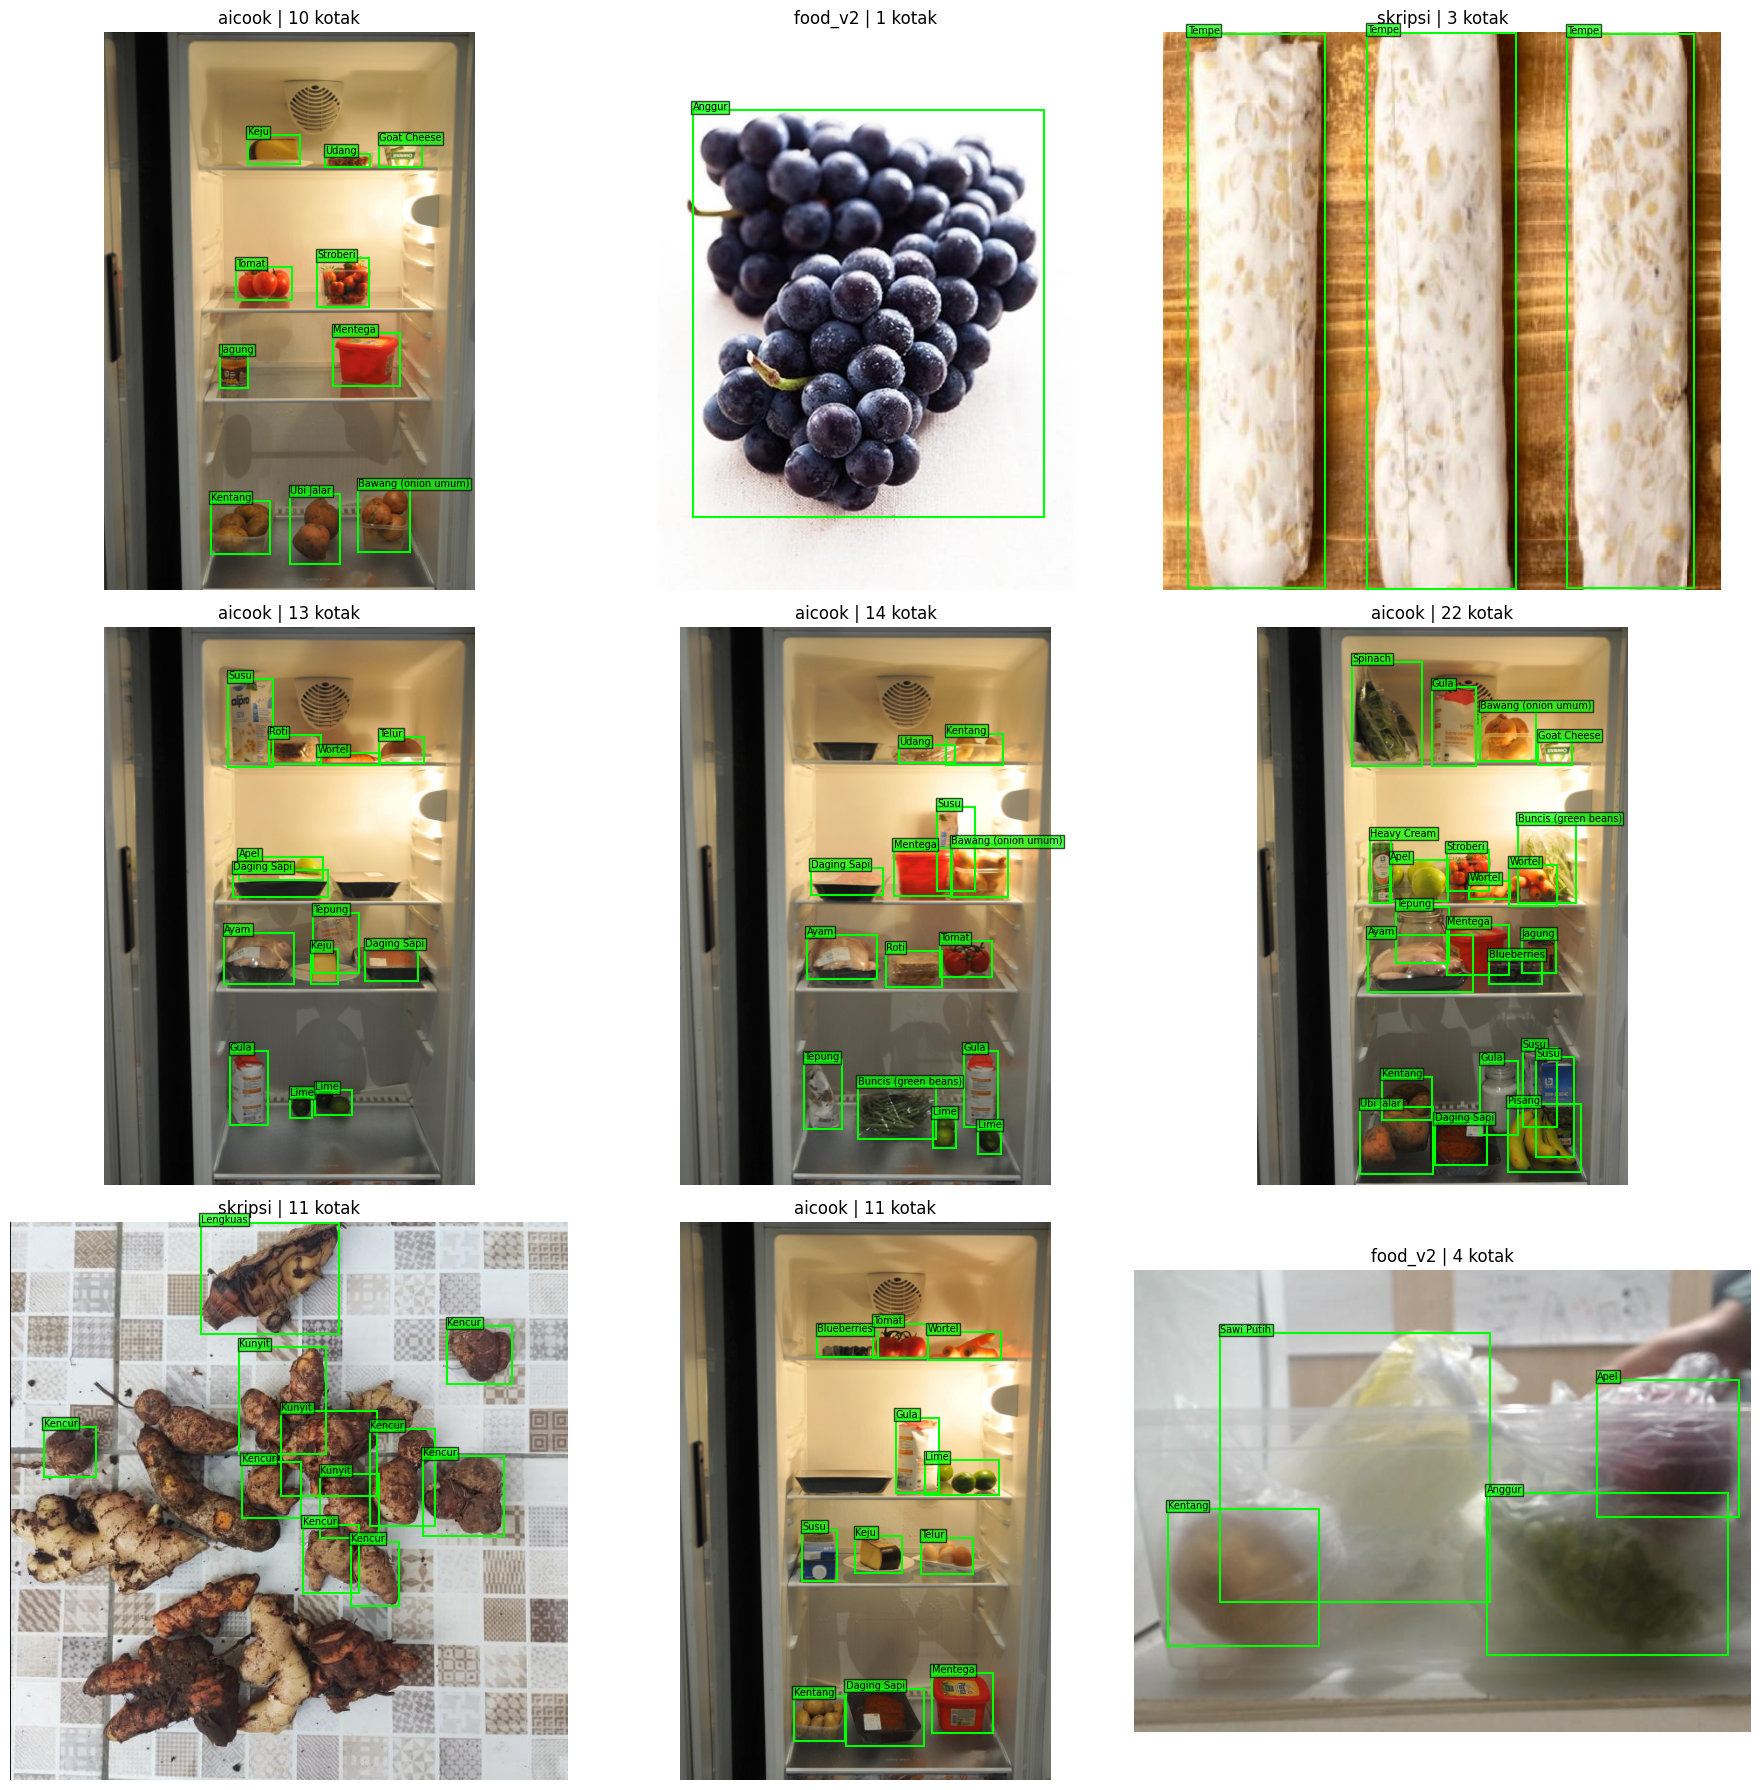

In [11]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

rng = random.Random(SEED)
preview = []
for source in sorted({r["source"] for r in selected_rows}):
    candidates = [r for r in selected_rows if r["source"] == source and r["split"] == "train"]
    if candidates: preview.append(rng.choice(candidates))
mixed_candidates = [r for r in selected_rows if len({b[0] for b in r["labels"]}) >= 2 and r not in preview]
preview += rng.sample(mixed_candidates, min(6, len(mixed_candidates)))
fig, axes = plt.subplots(3, 3, figsize=(18, 18))
for ax in axes.flat: ax.axis("off")
for ax, row in zip(axes.flat, preview):
    with Image.open(row["file"]) as original: image = original.convert("RGB")
    ax.imshow(image); ax.set_title(f"{row['source']} | {len(row['labels'])} kotak")
    for name, x, y, w, h in row["labels"]:
        x0, y0 = (x-w/2)*image.width, (y-h/2)*image.height
        ax.add_patch(Rectangle((x0, y0), w*image.width, h*image.height,
                               linewidth=1.5, edgecolor="lime", facecolor="none"))
        ax.text(x0, y0, name, color="black", fontsize=7, bbox=dict(facecolor="lime", alpha=.7, pad=1))
plt.tight_layout(); plt.show()


## 8. Training YOLOv8s

Mosaic dipakai selama training dan dimatikan pada 5 epoch terakhir; augmentasi ini tidak membuat
foto uji baru. Model awal `yolov8s.pt` diunduh otomatis. `best.pt` dipilih berdasarkan validasi,
sedangkan test digunakan pada sel 9. Tidak ada janji skor tertentu.

Jika CUDA out of memory, turunkan BATCH menjadi 4 atau IMGSZ menjadi 640, lalu ulangi sel pengaturan
dan training dengan run baru. Jangan memakai `resume` untuk mengganti dataset/ontologi.
Untuk melanjutkan run terputus: ulangi persiapan data yang sama, isi RESUME_FROM dengan path last.pt
yang tersimpan, lalu jalankan sel ini. Runtime baru tetap memerlukan unduhan dataset lagi.


In [6]:
import torch
import json
import hashlib
import shutil
import pandas as pd
import yaml
from pathlib import Path

ROOT = Path("/content/NakEnaMerged")
pilihan = sorted(ROOT.glob("merged_*/data.yaml"))

if not pilihan:
    raw = list((ROOT / "raw").glob("*/data.yaml"))
    if raw:
        raise RuntimeError(
            "Dataset mentah masih ada. Cukup jalankan sel helper/audit "
            "(5) dan penggabungan (6), tanpa download ulang."
        )
    raise RuntimeError(
        "File dataset tidak ditemukan di runtime ini. "
        "Kirim pesan ini dulu; jangan langsung ulang semuanya."
    )

if len(pilihan) == 1:
    DATA_YAML = pilihan[0]
else:
    for nomor, path in enumerate(pilihan, 1):
        print(nomor, path)
    nomor = int(input("Pilih nomor dataset yang tadi dipakai: "))
    DATA_YAML = pilihan[nomor - 1]

MERGED_DIR = DATA_YAML.parent
report = MERGED_DIR / "reports"

manifest_df = pd.read_csv(
    report / "image_manifest.csv",
    dtype={"uid": str, "group_id": str, "pixel_hash": str}
)

metadata = yaml.safe_load(DATA_YAML.read_text())
names = metadata["names"]
names = (
    dict(enumerate(names))
    if isinstance(names, list)
    else {int(k): v for k, v in names.items()}
)

provenance = json.loads((report / "provenance.json").read_text())
PROFILE = provenance["profile"]

selected_rows = manifest_df.to_dict("records")
for row in selected_rows:
    gambar = Path(row["merged_image"])
    if not gambar.is_file():
        raise FileNotFoundError(f"Gambar sudah tidak ada: {gambar}")

    label = gambar.parent.parent / "labels" / (gambar.stem + ".txt")
    row["labels"] = []
    for baris in label.read_text().splitlines():
        if baris.strip():
            cls, x, y, w, h = baris.split()
            row["labels"].append(
                (names[int(cls)], float(x), float(y), float(w), float(h))
            )

def label_signature(row):
    return tuple(sorted(
        (b[0], *(round(v, 5) for v in b[1:]))
        for b in row["labels"]
    ))

EPOCHS = int(globals().get("EPOCHS", 25))
IMGSZ = int(globals().get("IMGSZ", 800))
BATCH = int(globals().get("BATCH", 8))
SEED = int(globals().get("SEED", provenance.get("seed", 42)))
RESUME_FROM = str(globals().get("RESUME_FROM", ""))

drive_output = Path("/content/drive/MyDrive/NakEna_YOLO_Gabungan")
OUTPUT_ROOT = Path(globals().get(
    "OUTPUT_ROOT",
    drive_output if drive_output.parent.is_dir() else ROOT / "outputs"
))
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

mixed_test = manifest_df[
    (manifest_df["split"] == "test") &
    (manifest_df["n_classes"] >= 2)
]
MIXED_YAML = MERGED_DIR / "mixed_test.yaml"

print("Pulih:", DATA_YAML)
print("Jumlah gambar:", len(selected_rows))
print("Profil:", PROFILE)
print("Epoch:", EPOCHS, "| Input:", IMGSZ, "| Batch:", BATCH)
print("Lokasi hasil:", OUTPUT_ROOT)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Pulih: /content/NakEnaMerged/merged_uji_awal/data.yaml
Jumlah gambar: 15516
Profil: uji_awal
Epoch: 25 | Input: 800 | Batch: 8
Lokasi hasil: /content/drive/MyDrive/NakEna_YOLO_Gabungan


In [7]:
import torch
import hashlib
import json
import shutil
from pathlib import Path

from ultralytics import YOLO
from datetime import datetime

from ultralytics import YOLO
from datetime import datetime

if not torch.cuda.is_available():
    raise RuntimeError("GPU belum aktif. Pilih Runtime → Change runtime type → T4 GPU, lalu jalankan ulang sel berurutan.")
if not Path(DATA_YAML).is_file():
    raise RuntimeError("Dataset gabungan belum siap.")
train_records = [r for r in selected_rows if r["split"] == "train"]
if not train_records:
    raise RuntimeError("Split train kosong; periksa hasil pengelompokan pada sel 6.")

# Identitas data ditulis sebelum training supaya resume tidak mencampur eksperimen.
fingerprint = hashlib.sha256()
for row in sorted(selected_rows, key=lambda r: r["uid"]):
    fingerprint.update(json.dumps([row["uid"], row["split"], label_signature(row)], ensure_ascii=False).encode())
data_signature = fingerprint.hexdigest()

if RESUME_FROM.strip():
    checkpoint = Path(RESUME_FROM.strip())
    if not checkpoint.is_file(): raise FileNotFoundError("last.pt tidak ditemukan.")
    signature_file = checkpoint.parent.parent / "training_data.sha256"
    if not signature_file.is_file() or signature_file.read_text().strip() != data_signature:
        raise RuntimeError("Identitas data berbeda atau belum tercatat. Resume memerlukan sumber, versi, mapping, profil, dan split yang sama; gunakan training baru untuk data yang berubah.")
    model = YOLO(str(checkpoint))
    train_result = model.train(resume=True, device=0)
else:
    model = YOLO("yolov8s.pt")
    run_name = "nakena_gabungan_" + PROFILE + "_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    planned_run = OUTPUT_ROOT / "runs" / run_name
    planned_run.mkdir(parents=True, exist_ok=False)
    (planned_run / "training_data.sha256").write_text(data_signature + "\n")
    shutil.copytree(MERGED_DIR / "reports", planned_run / "dataset_reports")
    shutil.copy2(DATA_YAML, planned_run / "dataset_data.yaml")
    train_result = model.train(
        data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH,
        device=0, workers=2, cache=False, seed=SEED, deterministic=True,
        patience=10, mosaic=1.0, close_mosaic=min(5, max(0, EPOCHS-1)),
        mixup=0.0, project=str(OUTPUT_ROOT / "runs"), name=run_name,
        save=True, save_period=5, plots=True, exist_ok=True,
    )
RUN_DIR = Path(model.trainer.save_dir)
BEST_PT = RUN_DIR / "weights" / "best.pt"
assert BEST_PT.is_file(), "best.pt belum ditemukan"
best_model = YOLO(str(BEST_PT))
shutil.copytree(MERGED_DIR / "reports", RUN_DIR / "dataset_reports", dirs_exist_ok=True)
shutil.copy2(DATA_YAML, RUN_DIR / "dataset_data.yaml")
print("Run:", RUN_DIR)
print("Bobot terbaik:", BEST_PT)


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=5, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/NakEnaMerged/merged_uji_awal/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=800, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=nakena_gabungan_uji_awal_20261

## 9. Evaluasi test keseluruhan dan test foto campuran

Kedua evaluasi menggunakan `best.pt` yang sama. Subset campuran hanya berisi gambar **test**
dengan >=2 kelas bahan, tidak mengambil gambar train/val. Angka kecil atau foto dari satu kamera
belum mewakili semua foto pengguna. Periksa komposisi sumber di bawah saat membaca skor campuran.


In [8]:
test_metrics = best_model.val(
    data=str(DATA_YAML), split="test", imgsz=IMGSZ, batch=BATCH,
    device=0, workers=2, project=str(RUN_DIR / "evaluations"), name="test_all",
    plots=True, exist_ok=True,
)
evaluation = [{"Subset": "Semua test", "Gambar": int((manifest_df['split'] == 'test').sum()),
               "Precision": float(test_metrics.box.mp), "Recall": float(test_metrics.box.mr),
               "mAP50": float(test_metrics.box.map50), "mAP50-95": float(test_metrics.box.map)}]
if len(mixed_test):
    display(mixed_test.groupby("source").size().rename("Foto test campuran").to_frame())
    mixed_metrics = best_model.val(
        data=str(MIXED_YAML), split="test", imgsz=IMGSZ, batch=BATCH,
        device=0, workers=2, project=str(RUN_DIR / "evaluations"), name="test_mixed",
        plots=True, exist_ok=True,
    )
    evaluation.append({"Subset": "Test >=2 jenis bahan", "Gambar": len(mixed_test),
                       "Precision": float(mixed_metrics.box.mp), "Recall": float(mixed_metrics.box.mr),
                       "mAP50": float(mixed_metrics.box.map50), "mAP50-95": float(mixed_metrics.box.map)})
else:
    print("Tidak ada foto test berlabel >=2 kelas. Evaluasi khusus campuran tidak dibuat.")
evaluation_df = pd.DataFrame(evaluation)
display(evaluation_df)
evaluation_df.to_csv(RUN_DIR / "evaluation_summary.csv", index=False)


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 72 layers, 11,154,996 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1037.3±513.6 MB/s, size: 43.9 KB)
val: Scanning /content/NakEnaMerged/merged_uji_awal/test/labels... 1594 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 1594/1594 1.4Kit/s 1.1s
val: New cache created: /content/NakEnaMerged/merged_uji_awal/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 200/200 18.6it/s 10.7s
                   all       1594       4607      0.792      0.796       0.83      0.611
               Alpukat         13         27      0.788      0.889      0.906      0.711
                Anggur         22         36      0.852      0.667       0.73      0.563
                  Apel         58        117      0.613      0.821      0.795      0.618
                  Ayam

,Foto test campuran
source,
aicook,94
food_v2,89
skripsi,25


Ultralytics 8.4.215 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (NVIDIA A100-SXM4-80GB, 81153MiB)
Model summary (fused): 72 layers, 11,154,996 parameters, 0 gradients, 28.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2237.0±1135.4 MB/s, size: 146.0 KB)
val: Scanning /content/NakEnaMerged/merged_uji_awal/test/labels... 208 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 208/208 1.4Kit/s 0.1s
val: New cache created: /content/NakEnaMerged/merged_uji_awal/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 26/26 11.5it/s 2.3s
                   all        208       1969      0.808      0.757      0.791      0.566
               Alpukat          1          1          0          0     0.0622     0.0373
                Anggur          6         11      0.639      0.273      0.409      0.316
                  Apel         49         87      0.606      0.759      0.733      0.536
                  Ayam    

,Subset,Gambar,Precision,Recall,mAP50,mAP50-95
0,Semua test,1594,0.792375,0.796284,0.830425,0.611326
1,Test >=2 jenis bahan,208,0.807982,0.757108,0.791017,0.565689


## 10. Coba foto sendiri

Upload `bumbues.jpg` dan/atau foto lain yang **tidak digunakan untuk training**.
Hasil menampilkan semua kotak untuk setiap foto. Confidence 0,25 adalah pengaturan awal,
bukan pembatas jumlah jenis bahan. Penurunan confidence bisa menambah prediksi salah.


Saving bumbues.jpg to bumbues (11).jpg

0: 544x800 1 Alpukat, 1 Ayam, 4 Bawang Putihs, 2 Cabai (umum)s, 2 Jahes, 1 Terong, 2 Wortels, 9.4ms
Speed: 2.8ms preprocess, 9.4ms inference, 2.3ms postprocess per image at shape (1, 3, 544, 800)
Results saved to /content/drive/MyDrive/NakEna_YOLO_Gabungan/runs/nakena_gabungan_uji_awal_20261117_105453_728459/predictions/user_photos

Foto: bumbues (11).jpg | objek: 13


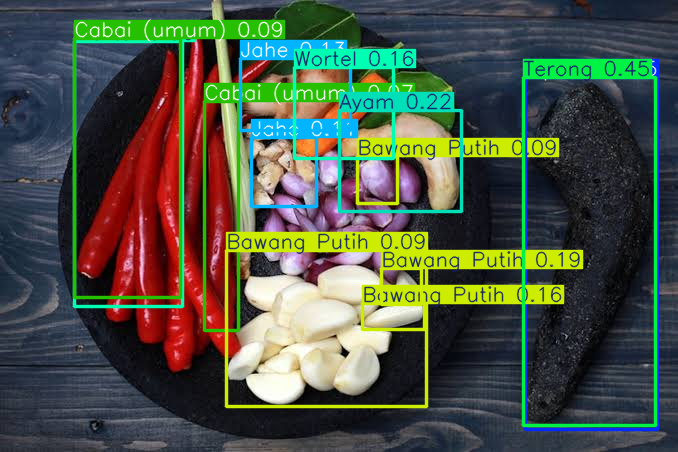

,Foto,Bahan,Confidence,xyxy
0,bumbues (11).jpg,Terong,0.4508,"[523.757629, 77.41433, 655.48584, 425.559326]"
1,bumbues (11).jpg,Ayam,0.2235,"[339.701477, 110.815201, 461.838379, 211.999329]"
2,bumbues (11).jpg,Bawang Putih,0.1888,"[381.888367, 268.953735, 421.627319, 304.986786]"
3,bumbues (11).jpg,Bawang Putih,0.1616,"[362.201874, 303.534943, 424.242035, 329.566742]"
4,bumbues (11).jpg,Wortel,0.1610,"[294.344971, 67.162086, 393.699554, 158.48082]"
5,bumbues (11).jpg,Alpukat,0.1548,"[525.508972, 77.197647, 657.853088, 429.489258]"
6,bumbues (11).jpg,Jahe,0.1274,"[240.709503, 58.101498, 350.583557, 130.850037]"
7,bumbues (11).jpg,Jahe,0.1125,"[251.239227, 137.136902, 316.42926, 206.549576]"
8,bumbues (11).jpg,Bawang Putih,0.0941,"[357.507782, 156.832016, 397.495056, 203.731033]"
9,bumbues (11).jpg,Cabai (umum),0.0861,"[74.94825, 38.733452, 180.889755, 297.947815]"


In [28]:
from pathlib import Path
import pandas as pd
from google.colab import files
from IPython.display import display
from PIL import Image

CONFIDENCE = 0.05  # @param {type:"number"}
uploaded = files.upload()
if not uploaded: raise ValueError("Belum ada foto dipilih.")
test_upload_dir = ROOT / "user_test"
test_upload_dir.mkdir(exist_ok=True)
image_paths = []
for filename, data in uploaded.items():
    path = test_upload_dir / Path(filename).name
    path.write_bytes(data); image_paths.append(str(path))
predictions = best_model.predict(
    source=image_paths, imgsz=IMGSZ, conf=CONFIDENCE, iou=0.6,
    max_det=300, agnostic_nms=False, save=True,
    project=str(RUN_DIR / "predictions"), name="user_photos", exist_ok=True,
)
prediction_rows = []
for result in predictions:
    print("\nFoto:", Path(result.path).name, "| objek:", len(result.boxes))
    display(Image.fromarray(result.plot()[..., ::-1]))
    for box in result.boxes:
        prediction_rows.append({"Foto": Path(result.path).name,
                                "Bahan": result.names[int(box.cls.item())],
                                "Confidence": round(float(box.conf.item()), 4),
                                "xyxy": box.xyxy[0].cpu().tolist()})
prediction_df = pd.DataFrame(prediction_rows, columns=["Foto", "Bahan", "Confidence", "xyxy"])
display(prediction_df)
prediction_df.to_json(RUN_DIR / "user_photo_predictions.json", orient="records", force_ascii=False, indent=2)



Foto: bumbues (11).jpg | objek: 13


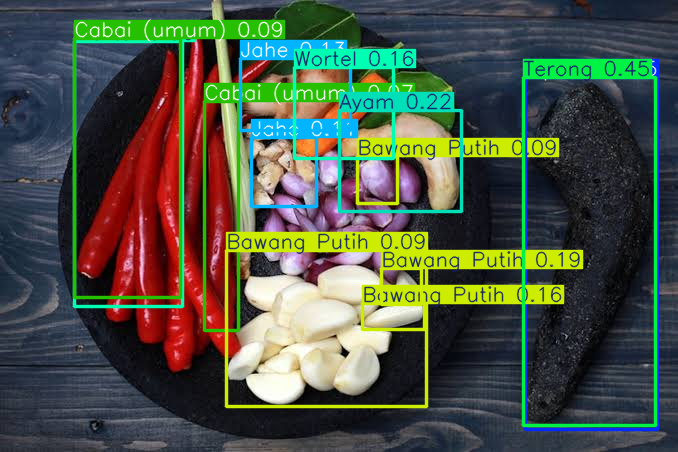

,Foto,Bahan,Confidence,xyxy
0,bumbues (11).jpg,Terong,0.4508,"[523.757629, 77.41433, 655.48584, 425.559326]"
1,bumbues (11).jpg,Ayam,0.2235,"[339.701477, 110.815201, 461.838379, 211.999329]"
2,bumbues (11).jpg,Bawang Putih,0.1888,"[381.888367, 268.953735, 421.627319, 304.986786]"
3,bumbues (11).jpg,Bawang Putih,0.1616,"[362.201874, 303.534943, 424.242035, 329.566742]"
4,bumbues (11).jpg,Wortel,0.1610,"[294.344971, 67.162086, 393.699554, 158.48082]"
5,bumbues (11).jpg,Alpukat,0.1548,"[525.508972, 77.197647, 657.853088, 429.489258]"
6,bumbues (11).jpg,Jahe,0.1274,"[240.709503, 58.101498, 350.583557, 130.850037]"
7,bumbues (11).jpg,Jahe,0.1125,"[251.239227, 137.136902, 316.42926, 206.549576]"
8,bumbues (11).jpg,Bawang Putih,0.0941,"[357.507782, 156.832016, 397.495056, 203.731033]"
9,bumbues (11).jpg,Cabai (umum),0.0861,"[74.94825, 38.733452, 180.889755, 297.947815]"


In [29]:
from PIL import Image
from IPython.display import display
from pathlib import Path
import pandas as pd

prediction_rows = []

for result in predictions:
    print(
        "\nFoto:", Path(result.path).name,
        "| objek:", len(result.boxes)
    )
    display(Image.fromarray(result.plot()[..., ::-1]))

    for box in result.boxes:
        prediction_rows.append({
            "Foto": Path(result.path).name,
            "Bahan": result.names[int(box.cls.item())],
            "Confidence": round(float(box.conf.item()), 4),
            "xyxy": box.xyxy[0].cpu().tolist()
        })

prediction_df = pd.DataFrame(
    prediction_rows,
    columns=["Foto", "Bahan", "Confidence", "xyxy"]
)
display(prediction_df)

prediction_df.to_json(
    Path(RUN_DIR) / "user_photo_predictions.json",
    orient="records",
    force_ascii=False,
    indent=2
)

## 11. Unduh model dan laporan

ZIP berisi **best.pt**, nama kelas, pemetaan label, provenance/lisensi sumber, ringkasan audit,
manifest split, dan hasil evaluasi yang sudah dijalankan. Foto dataset dan API key tidak disertakan.
Kelas model gabungan lebih luas dari model 21 kelas sebelumnya; backend NakEna harus membaca
`model.names` atau `classes.json`, bukan memakai urutan class ID model lama.


In [30]:
from zipfile import ZipFile, ZIP_DEFLATED
from importlib.metadata import version as package_version

if not BEST_PT.is_file(): raise FileNotFoundError("best.pt belum tersedia.")
package_path = RUN_DIR / "NakEna_YOLO_Gabungan_Model.zip"
versions = {name: package_version(name) for name in ["ultralytics", "roboflow", "torch", "Pillow", "pandas"]}
(RUN_DIR / "package_versions.json").write_text(json.dumps(versions, indent=2))
with ZipFile(package_path, "w", ZIP_DEFLATED) as archive:
    archive.write(BEST_PT, "best.pt")
    archive.write(RUN_DIR / "dataset_data.yaml", "dataset_data.yaml")
    archive.write(RUN_DIR / "package_versions.json", "package_versions.json")
    for path in (RUN_DIR / "dataset_reports").rglob("*"):
        if path.is_file(): archive.write(path, "dataset_reports/" + str(path.relative_to(RUN_DIR / "dataset_reports")))
    for name in ["args.yaml", "results.csv", "results.png", "evaluation_summary.csv", "user_photo_predictions.json", "training_data.sha256"]:
        path = RUN_DIR / name
        if path.is_file(): archive.write(path, name)
print("Model:", BEST_PT)
print("Paket:", package_path)
files.download(str(package_path))


Model: /content/drive/MyDrive/NakEna_YOLO_Gabungan/runs/nakena_gabungan_uji_awal_20261117_105453_728459/weights/best.pt
Paket: /content/drive/MyDrive/NakEna_YOLO_Gabungan/runs/nakena_gabungan_uji_awal_20261117_105453_728459/NakEna_YOLO_Gabungan_Model.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Catatan penggunaan hasil

- Jalur ini menghasilkan file model lokal `best.pt`; berbeda dengan penggunaan Gemini Vision API.
- Tidak semua subjenis kelas digabung otomatis. Review `class_mapping.csv`, khususnya onion/chili,
  white_rice dan label numerik. Jika mapping diperbaiki, ulangi audit/merge dan mulai training baru.
- Penggabungan label tidak otomatis melabeli objek yang terlewat pada foto sumber. Foto campuran
  tetap perlu diperiksa secara visual. Gunakan hasil audit untuk menentukan perbaikan selanjutnya.
- `data.yaml` dalam paket mengacu ke path dataset Colab untuk dokumentasi; file tersebut tidak
  membawa foto training. Untuk inferensi backend cukup bobot dan nama kelas yang sesuai.
- Mode penuh tetap dapat mengalami ketimpangan kelas/sumber. Periksa laporan dan skor per kelas
  sebelum menganggap model siap menggantikan model yang sekarang.

Sumber: [Roboflow Python SDK](https://github.com/roboflow/roboflow-python),
[fork_project](https://github.com/roboflow/roboflow-python/blob/main/roboflow/core/workspace.py),
[versi/download](https://github.com/roboflow/roboflow-python/blob/main/roboflow/core/version.py),
[format YOLO](https://docs.ultralytics.com/datasets/detect/),
[training Ultralytics](https://docs.ultralytics.com/modes/train/).

Notebook dibuat tanpa API key dan tanpa menjalankan download/training pada akun pengguna.
Statistik dan hasil model yang sebenarnya akan muncul saat notebook dijalankan di Colab.
